# HybridSN — Salinas spatial-split experiment (batch 128, fixed epochs)

This notebook adapts **HybridSN** (3D spectral–spatial CNN followed by a 2D spatial CNN) to the project's fixed Salinas spatial benchmark. The public reference implementation is Keras-based; this notebook implements the same high-level 3D→2D feature hierarchy in PyTorch.

**Benchmark protocol:** seed 42; saved `salinas_spatial_split_seed42.npz`; 32×32 spatial blocks; 15×15 centered patches; shared PCA-30 artifact fitted only from training patches; validation Macro-F1 checkpoint selection without early stopping. Training always runs for all 50 requested epochs. This keeps the input/split protocol aligned with the project's other spatial-split experiments.

**Faithfulness note:** the paper's layerwise example uses 25×25 patches and PCA-30. This benchmark uses 15×15 patches to preserve the project's common spatial protocol, so the flattening dimension and classifier parameter count differ from the paper's tabulated 25×25 example. Treat this as a **paper-guided PyTorch adaptation**, not an exact reproduction of the authors' Keras notebook. Reference: https://github.com/gokriznastic/HybridSN and https://doi.org/10.1109/LGRS.2019.2918719.

**Training configuration:** batch size 128 for train/validation/test; 50 epochs; AdamW (learning rate 1e-3, weight decay 1e-4); CosineAnnealingLR; dropout 0.4; best validation Macro-F1 checkpoint is retained, but training does not stop early. Batch size 128 may exceed the memory available on a 4 GB GPU; if CUDA runs out of memory, the requested batch size cannot run on that device without memory-saving changes.


In [1]:
from pathlib import Path
import sys, os, json, hashlib, random, platform

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import joblib

from dfm.data.salinas import SALINAS_CLASS_NAMES, SalinasPatchDataset, load_salinas

SEED = 42
PATCH_SIZE = 15
BLOCK_SIZE = 32
PCA_COMPONENTS = 30
BATCH_SIZE = 128
EVAL_BATCH_SIZE = BATCH_SIZE
EPOCHS = 50
LR = 1e-3
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 0

OUTPUTS = PROJECT_ROOT / "outputs" / "salinas"
OUTPUTS.mkdir(parents=True, exist_ok=True)
DATA_DIR = PROJECT_ROOT / "data" / "raw" / "salinas"
SPLIT_PATH = OUTPUTS / "salinas_spatial_split_seed42.npz"
PCA_PATH = OUTPUTS / "salinas_pca_30.joblib"
PCA_CONFIG_PATH = OUTPUTS / "salinas_pca_30_config.json"
MODEL_NAME = "hybridsn_pca30_spatial_bs128_fixed50"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Project root:", PROJECT_ROOT)
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)

c:\Users\Dines\Documents\Codex\2026-05-15\files-mentioned-by-the-user-dataset0\dense-forest-monitoring_backup\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Project root: c:\Users\Dines\Documents\Codex\2026-05-15\files-mentioned-by-the-user-dataset0\dense-forest-monitoring_backup
Device: cuda
GPU: NVIDIA GeForce RTX 2050
PyTorch: 2.5.1+cu118


In [2]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

scene = load_salinas(DATA_DIR, download=True)
if scene.bands != 204:
    raise ValueError(f"Expected corrected Salinas with 204 bands, found {scene.bands}.")
if len(SALINAS_CLASS_NAMES) != 16:
    raise ValueError("Expected 16 Salinas classes.")

rows, cols = np.where(scene.labels > 0)
labels = scene.labels[rows, cols].astype(np.int64) - 1
print("Cube (H,W,C):", scene.cube.shape)
print("Labeled pixels:", len(labels))
print("Classes:", len(SALINAS_CLASS_NAMES))

Cube (H,W,C): (512, 217, 204)
Labeled pixels: 54129
Classes: 16


In [3]:
if not SPLIT_PATH.exists():
    raise FileNotFoundError(
        f"Required shared spatial split not found: {SPLIT_PATH}. "
        "Run the project's spatial-split preparation notebook first; do not silently create a different split."
    )
split = np.load(SPLIT_PATH)
train_indices = split["train_indices"].astype(np.int64)
val_indices = split["val_indices"].astype(np.int64)
test_indices = split["test_indices"].astype(np.int64)

if set(train_indices) & set(val_indices) or set(train_indices) & set(test_indices) or set(val_indices) & set(test_indices):
    raise ValueError("Split index overlap detected.")
if max(np.concatenate([train_indices, val_indices, test_indices])) >= len(labels):
    raise ValueError("Saved split indices are incompatible with current labeled-pixel ordering.")

# Verify that each center pixel belongs to the expected 32x32 spatial block split.
def block_set(indices):
    return set(zip((rows[indices] // BLOCK_SIZE).tolist(), (cols[indices] // BLOCK_SIZE).tolist()))
train_blocks, val_blocks, test_blocks = map(block_set, (train_indices, val_indices, test_indices))
if train_blocks & val_blocks or train_blocks & test_blocks or val_blocks & test_blocks:
    raise ValueError("Spatial block leakage detected: a block occurs in more than one split.")

print("Loaded shared split:", SPLIT_PATH)
print("Train / val / test:", len(train_indices), len(val_indices), len(test_indices))
print("Spatial blocks train / val / test:", len(train_blocks), len(val_blocks), len(test_blocks))

Loaded shared split: c:\Users\Dines\Documents\Codex\2026-05-15\files-mentioned-by-the-user-dataset0\dense-forest-monitoring_backup\outputs\salinas\salinas_spatial_split_seed42.npz
Train / val / test: 32337 10952 10840
Spatial blocks train / val / test: 49 16 16


In [4]:
base_train = SalinasPatchDataset(scene, indices=train_indices, patch_size=PATCH_SIZE, normalize=True)
base_val = SalinasPatchDataset(scene, indices=val_indices, patch_size=PATCH_SIZE, normalize=True)
base_test = SalinasPatchDataset(scene, indices=test_indices, patch_size=PATCH_SIZE, normalize=True)

# Use the common PCA-30 artifact if it exists; otherwise fit it only on training patches.
if PCA_PATH.exists() and PCA_CONFIG_PATH.exists():
    pca = joblib.load(PCA_PATH)
    with open(PCA_CONFIG_PATH, "r", encoding="utf-8") as f:
        pca_config = json.load(f)
    if getattr(pca, "n_components_", None) != PCA_COMPONENTS:
        raise ValueError("Existing PCA artifact is not PCA-30.")
    print("Loaded common PCA artifact:", PCA_PATH)
else:
    rng = np.random.default_rng(SEED)
    n_selected = min(2000, len(base_train))
    selected = rng.choice(len(base_train), size=n_selected, replace=False)
    patches = np.stack([base_train[int(i)][0] for i in selected]).astype(np.float32)
    spectra = patches.transpose(0, 2, 3, 1).reshape(-1, patches.shape[1])
    max_vectors = 200_000
    if len(spectra) > max_vectors:
        keep = rng.choice(len(spectra), size=max_vectors, replace=False)
        spectra = spectra[keep]
    pca = PCA(n_components=PCA_COMPONENTS, svd_solver="randomized", random_state=SEED)
    pca.fit(spectra)
    pca_config = {
        "artifact": PCA_PATH.name,
        "components": PCA_COMPONENTS,
        "patches_sampled": int(n_selected),
        "spectral_vectors_used": int(len(spectra)),
        "svd_solver": "randomized",
        "random_state": SEED,
        "fit_source": "training patches only",
    }
    joblib.dump(pca, PCA_PATH)
    with open(PCA_CONFIG_PATH, "w", encoding="utf-8") as f:
        json.dump(pca_config, f, indent=2)
    print("Fitted and saved common PCA artifact:", PCA_PATH)

class PCAPatchDataset(Dataset):
    def __init__(self, base_dataset, pca):
        self.base_dataset = base_dataset
        self.pca = pca
    def __len__(self):
        return len(self.base_dataset)
    def __getitem__(self, idx):
        patch, label = self.base_dataset[idx]  # [204,H,W]
        c, h, w = patch.shape
        reduced = self.pca.transform(patch.transpose(1, 2, 0).reshape(-1, c))
        reduced = reduced.reshape(h, w, -1).transpose(2, 0, 1).astype(np.float32)
        return torch.from_numpy(reduced), torch.tensor(int(label), dtype=torch.long)

train_dataset = PCAPatchDataset(base_train, pca)
val_dataset = PCAPatchDataset(base_val, pca)
test_dataset = PCAPatchDataset(base_test, pca)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_dataset, batch_size=EVAL_BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_dataset, batch_size=EVAL_BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())

x_batch, y_batch = next(iter(train_loader))
print("PCA patch batch:", tuple(x_batch.shape), "labels:", tuple(y_batch.shape))

Loaded common PCA artifact: c:\Users\Dines\Documents\Codex\2026-05-15\files-mentioned-by-the-user-dataset0\dense-forest-monitoring_backup\outputs\salinas\salinas_pca_30.joblib
PCA patch batch: (128, 30, 15, 15) labels: (128,)


## HybridSN model

The model follows the paper's feature hierarchy: three valid 3D convolution layers, reshape/merge of the spectral-depth and feature channels, one valid 2D convolution layer, then Flatten → Dense(256) → Dropout → Dense(128) → Dropout → class logits. PyTorch uses `[batch, channel, spectral_depth, height, width]` for the 3D convolutions.

In [5]:
class HybridSN(nn.Module):
    def __init__(self, num_classes=16, pca_components=30, patch_size=15, dropout=0.4):
        super().__init__()
        if patch_size < 9:
            raise ValueError("Patch size must be at least 9 for the valid convolution stack.")
        # Input: [B, 1, PCA-depth=30, H, W]
        self.conv3d = nn.Sequential(
            nn.Conv3d(1, 8, kernel_size=(7, 3, 3), stride=1, padding=0),
            nn.ReLU(inplace=True),
            nn.Conv3d(8, 16, kernel_size=(5, 3, 3), stride=1, padding=0),
            nn.ReLU(inplace=True),
            nn.Conv3d(16, 32, kernel_size=(3, 3, 3), stride=1, padding=0),
            nn.ReLU(inplace=True),
        )
        spectral_depth = pca_components - 6 - 4 - 2
        spatial_size = patch_size - 2 - 2 - 2
        self.conv2d = nn.Sequential(
            nn.Conv2d(32 * spectral_depth, 64, kernel_size=3, stride=1, padding=0),
            nn.ReLU(inplace=True),
        )
        flatten_dim = 64 * (spatial_size - 2) * (spatial_size - 2)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flatten_dim, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        # x: [B, PCA components, H, W]
        x = x.unsqueeze(1)                  # [B,1,D,H,W]
        x = self.conv3d(x)                 # [B,32,D',H',W']
        b, c, d, h, w = x.shape
        x = x.reshape(b, c * d, h, w)      # merge spectral depth and channels
        x = self.conv2d(x)
        return self.classifier(x)

model = HybridSN(
    num_classes=len(SALINAS_CLASS_NAMES),
    pca_components=PCA_COMPONENTS,
    patch_size=PATCH_SIZE,
    dropout=0.4,
).to(device)

with torch.no_grad():
    demo_logits = model(x_batch[:2].to(device))
print("Smoke-test input:", tuple(x_batch[:2].shape))
print("Smoke-test output:", tuple(demo_logits.shape))
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

Smoke-test input: (2, 30, 15, 15)
Smoke-test output: (2, 16)
Trainable parameters: 1190016


In [6]:
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, total = 0.0, 0
    y_true, y_pred = [], []
    with torch.no_grad():
        for x, y in tqdm(loader, leave=False):
            x = x.to(device=device, dtype=torch.float32, non_blocking=True)
            y = y.to(device=device, dtype=torch.long, non_blocking=True)
            logits = model(x)
            loss = criterion(logits, y)
            total_loss += loss.item() * y.size(0)
            total += y.size(0)
            y_true.extend(y.cpu().numpy().tolist())
            y_pred.extend(logits.argmax(dim=1).cpu().numpy().tolist())
    return {
        "loss": total_loss / max(total, 1),
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }, np.asarray(y_true), np.asarray(y_pred)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

best_macro_f1 = -1.0
best_epoch = 0
best_state = None
history = []
patience_counter = 0

In [7]:
for epoch in range(1, EPOCHS + 1):  # fixed-length training: no early stopping
    model.train()
    running_loss, seen = 0.0, 0
    progress = tqdm(train_loader, desc=f"Epoch {epoch:02d}/{EPOCHS}", leave=False)
    for x, y in progress:
        x = x.to(device=device, dtype=torch.float32, non_blocking=True)
        y = y.to(device=device, dtype=torch.long, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * y.size(0)
        seen += y.size(0)
        progress.set_postfix(loss=f"{loss.item():.4f}")

    train_loss = running_loss / max(seen, 1)
    val_metrics, _, _ = evaluate(model, val_loader, criterion)
    scheduler.step()
    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_macro_f1": val_metrics["macro_f1"],
        "lr": optimizer.param_groups[0]["lr"],
    }
    history.append(row)
    print(f"Epoch {epoch:02d} | train loss {train_loss:.4f} | val OA {val_metrics['accuracy']:.4f} | val Macro-F1 {val_metrics['macro_f1']:.4f}")

    if val_metrics["macro_f1"] > best_macro_f1:
        best_macro_f1 = val_metrics["macro_f1"]
        best_epoch = epoch
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        torch.save({"model_state_dict": best_state, "best_epoch": best_epoch, "best_val_macro_f1": best_macro_f1}, OUTPUTS / f"{MODEL_NAME}_best_checkpoint.pt")

if best_state is None:
    raise RuntimeError("No checkpoint was selected.")
model.load_state_dict(best_state)
model.to(device)
print("Best epoch:", best_epoch)
print("Best validation Macro-F1:", best_macro_f1)

Epoch 01/50:   0%|          | 0/253 [00:00<?, ?it/s]

Epoch 01 | train loss 0.3806 | val OA 0.8647 | val Macro-F1 0.9091


Epoch 02 | train loss 0.0254 | val OA 0.9274 | val Macro-F1 0.9473


Epoch 03 | train loss 0.0111 | val OA 0.8548 | val Macro-F1 0.9141


Epoch 04 | train loss 0.0067 | val OA 0.8950 | val Macro-F1 0.9394


...

Epoch 46 | train loss 0.0000 | val OA 0.9262 | val Macro-F1 0.9653


Epoch 47 | train loss 0.0000 | val OA 0.9262 | val Macro-F1 0.9653


Epoch 48 | train loss 0.0000 | val OA 0.9263 | val Macro-F1 0.9650


Epoch 49 | train loss 0.0000 | val OA 0.9268 | val Macro-F1 0.9652


Epoch 50 | train loss 0.0001 | val OA 0.9270 | val Macro-F1 0.9656
Best epoch: 30
Best validation Macro-F1: 0.9744661601728997


In [8]:
test_metrics, y_test, y_pred = evaluate(model, test_loader, criterion)
print("FINAL SPATIAL TEST RESULTS (held-out test evaluated once after model selection)")
print(json.dumps(test_metrics, indent=2))
print("\nPer-class report:")
print(classification_report(y_test, y_pred, labels=np.arange(len(SALINAS_CLASS_NAMES)), target_names=SALINAS_CLASS_NAMES, digits=4, zero_division=0))

FINAL SPATIAL TEST RESULTS (held-out test evaluated once after model selection)
{
  "loss": 0.7732181088510914,
  "accuracy": 0.9476937269372694,
  "macro_f1": 0.922918587018231
}

Per-class report:
                           precision    recall  f1-score   support

    Brocoli_green_weeds_1     1.0000    1.0000    1.0000       909
    Brocoli_green_weeds_2     1.0000    1.0000    1.0000       498
                   Fallow     0.8506    1.0000    0.9193       296
        Fallow_rough_plow     1.0000    1.0000    1.0000       295
            Fallow_smooth     1.0000    1.0000    1.0000       863
                  Stubble     0.9984    1.0000    0.9992       632
                   Celery     1.0000    1.0000    1.0000       120
         Grapes_untrained     0.9915    0.8869    0.9363      2899
     Soil_vinyard_develop     1.0000    1.0000    1.0000      1177
Corn_senesced_green_weeds     0.9623    0.6562    0.7803       544
      Lettuce_romaine_4wk     0.3228    1.0000    0.4880       

In [9]:
history_df = pd.DataFrame(history)
history_path = OUTPUTS / f"{MODEL_NAME}_history.csv"
history_df.to_csv(history_path, index=False)

split_hashes = {
    "train": hashlib.sha256(np.ascontiguousarray(train_indices).tobytes()).hexdigest(),
    "val": hashlib.sha256(np.ascontiguousarray(val_indices).tobytes()).hexdigest(),
    "test": hashlib.sha256(np.ascontiguousarray(test_indices).tobytes()).hexdigest(),
}
checkpoint_path = OUTPUTS / f"{MODEL_NAME}_best.pt"
torch.save({
    "model_state_dict": best_state,
    "best_epoch": best_epoch,
    "best_val_macro_f1": best_macro_f1,
    "test_metrics": test_metrics,
    "seed": SEED,
    "patch_size": PATCH_SIZE,
    "block_size": BLOCK_SIZE,
    "pca_components": PCA_COMPONENTS,
    "batch_size": BATCH_SIZE,
    "epochs_completed": len(history),
    "lr": LR,
    "weight_decay": WEIGHT_DECAY,
    "split_path": str(SPLIT_PATH),
    "split_hashes": split_hashes,
    "pca_path": str(PCA_PATH),
}, checkpoint_path)
np.save(OUTPUTS / f"{MODEL_NAME}_y_test.npy", y_test)
np.save(OUTPUTS / f"{MODEL_NAME}_y_pred.npy", y_pred)
with open(OUTPUTS / f"{MODEL_NAME}_run_config.json", "w", encoding="utf-8") as f:
    json.dump({
        "model": "HybridSN paper-guided PyTorch adaptation",
        "seed": SEED,
        "patch_size": PATCH_SIZE,
        "block_size": BLOCK_SIZE,
        "pca_components": PCA_COMPONENTS,
        "batch_size": BATCH_SIZE,
        "epochs_requested": EPOCHS,
        "epochs_completed": len(history),
        "learning_rate": LR,
        "weight_decay": WEIGHT_DECAY,
        "optimizer": "AdamW",
        "scheduler": "CosineAnnealingLR",
        "checkpoint_selection": "best validation Macro-F1",
        "early_stopping": False,
        "training_policy": "run all requested epochs; retain best validation Macro-F1 checkpoint",
        "split_artifact": str(SPLIT_PATH),
        "split_hashes": split_hashes,
        "pca_artifact": str(PCA_PATH),
        "pca_config": pca_config,
        "test_metrics": test_metrics,
    }, f, indent=2)

print("Saved history:", history_path)
print("Saved checkpoint:", checkpoint_path)
print("Saved run configuration and predictions under:", OUTPUTS)

Saved history: c:\Users\Dines\Documents\Codex\2026-05-15\files-mentioned-by-the-user-dataset0\dense-forest-monitoring_backup\outputs\salinas\hybridsn_pca30_spatial_bs128_fixed50_history.csv
Saved checkpoint: c:\Users\Dines\Documents\Codex\2026-05-15\files-mentioned-by-the-user-dataset0\dense-forest-monitoring_backup\outputs\salinas\hybridsn_pca30_spatial_bs128_fixed50_best.pt
Saved run configuration and predictions under: c:\Users\Dines\Documents\Codex\2026-05-15\files-mentioned-by-the-user-dataset0\dense-forest-monitoring_backup\outputs\salinas


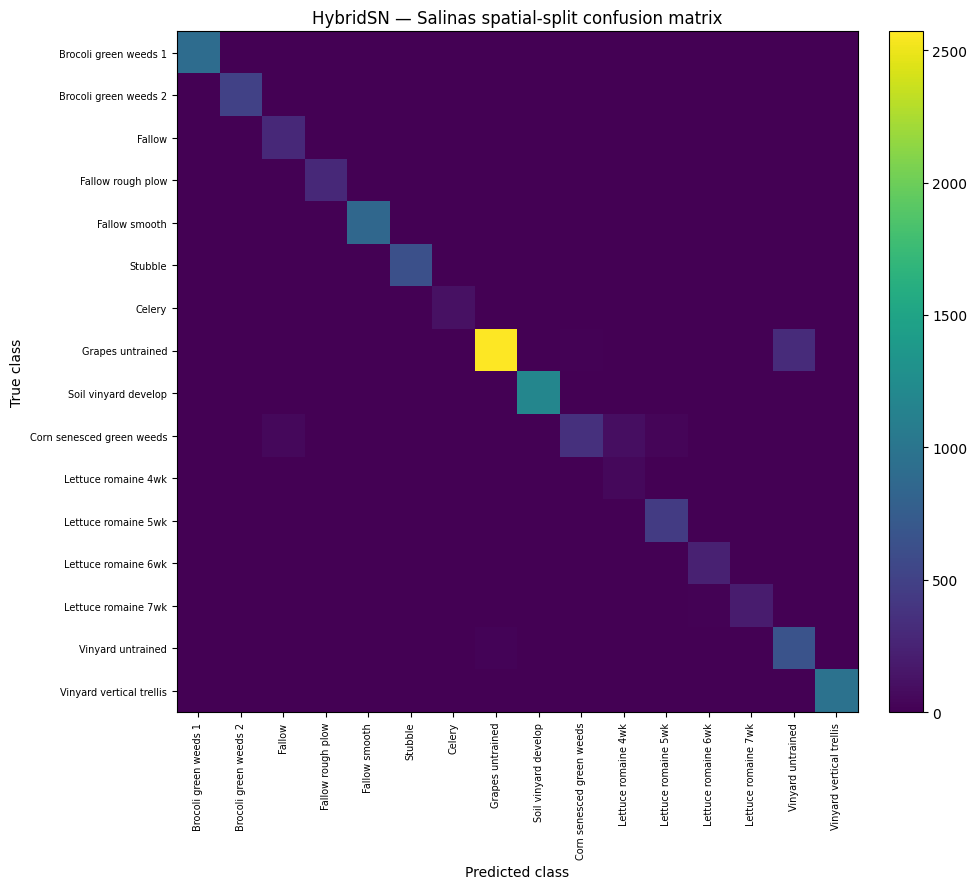

In [10]:
cm = confusion_matrix(y_test, y_pred, labels=np.arange(len(SALINAS_CLASS_NAMES)))
fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(cm, interpolation="nearest")
ax.set_title("HybridSN — Salinas spatial-split confusion matrix")
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_xticks(np.arange(len(SALINAS_CLASS_NAMES)))
ax.set_yticks(np.arange(len(SALINAS_CLASS_NAMES)))
ax.set_xticklabels([n.replace("_", " ") for n in SALINAS_CLASS_NAMES], rotation=90, fontsize=7)
ax.set_yticklabels([n.replace("_", " ") for n in SALINAS_CLASS_NAMES], fontsize=7)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
plt.show()

## Efficiency benchmark and results table

This cell benchmarks **inference** using the same table schema as the other model efficiency results. It records parameter count, model parameter size, optional FLOPs (if `thop` is installed), peak CUDA memory, batch latency statistics, throughput, and the held-out test accuracy/Macro-F1 already computed above. It writes a model-specific CSV and updates a shared efficiency table. FLOPs are left blank if the optional profiler is unavailable; they are not estimated or fabricated.

In [11]:
import time
import numpy as np
import pandas as pd
import torch
from pathlib import Path

WARMUP_RUNS = 20
TIMED_RUNS = 100

# Keep the model selected using validation Macro-F1 and measure inference only.
model.eval()
bench_device = next(model.parameters()).device
is_cuda = bench_device.type == "cuda"

# Use a full batch from the test loader when available, matching the configured batch size.
try:
    x_bench, _ = next(iter(test_loader))
except StopIteration:
    raise RuntimeError("test_loader is empty; cannot run efficiency benchmark.")
x_bench = x_bench.to(bench_device, dtype=torch.float32, non_blocking=True)
actual_batch_size = int(x_bench.shape[0])

# Parameter count and parameter-only model size (MB, decimal units).
parameter_count = sum(p.numel() for p in model.parameters())
trainable_parameter_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
model_size_mb = sum(p.numel() * p.element_size() for p in model.parameters()) / 1e6

# FLOPs are optional: report NaN if THOP is not installed or profiling fails.
flops = np.nan
gflops = np.nan
try:
    from thop import profile
    flops, _ = profile(model, inputs=(x_bench[:1],), verbose=False)
    gflops = float(flops) / 1e9
    flops = float(flops)
except Exception as exc:
    print(f"FLOPs not measured (install thop to enable): {exc}")

if is_cuda:
    torch.cuda.synchronize(bench_device)
    torch.cuda.reset_peak_memory_stats(bench_device)

latencies_ms = []
with torch.inference_mode():
    for _ in range(WARMUP_RUNS):
        _ = model(x_bench)
    if is_cuda:
        torch.cuda.synchronize(bench_device)

    for _ in range(TIMED_RUNS):
        if is_cuda:
            torch.cuda.synchronize(bench_device)
        t0 = time.perf_counter()
        _ = model(x_bench)
        if is_cuda:
            torch.cuda.synchronize(bench_device)
        latencies_ms.append((time.perf_counter() - t0) * 1000.0)

latencies_ms = np.asarray(latencies_ms, dtype=np.float64)
peak_gpu_memory_mb = (
    torch.cuda.max_memory_allocated(bench_device) / (1024 ** 2) if is_cuda else np.nan
)
mean_latency_ms = float(np.mean(latencies_ms))

# Accuracy and Macro-F1 are from the notebook's held-out spatial test evaluation.
row = {
    "model": "hybridsn",
    "accuracy": float(test_metrics["accuracy"]),
    "macro_f1": float(test_metrics["macro_f1"]),
    "parameters": int(parameter_count),
    "parameters_m": float(parameter_count / 1e6),
    "model_size_mb": float(model_size_mb),
    "flops": flops,
    "gflops": gflops,
    "peak_gpu_memory_mb": float(peak_gpu_memory_mb) if is_cuda else np.nan,
    "batch_size": actual_batch_size,
    "latency_batch_ms": mean_latency_ms,
    "latency_batch_median_ms": float(np.median(latencies_ms)),
    "latency_batch_p95_ms": float(np.percentile(latencies_ms, 95)),
    "latency_batch_std_ms": float(np.std(latencies_ms, ddof=1)) if len(latencies_ms) > 1 else 0.0,
    "latency_per_sample_ms": mean_latency_ms / actual_batch_size,
    "throughput_samples_sec": actual_batch_size / (mean_latency_ms / 1000.0),
    "warmup_runs": WARMUP_RUNS,
    "timed_runs": TIMED_RUNS,
}

results_dir = OUTPUTS
results_dir.mkdir(parents=True, exist_ok=True)
model_csv = results_dir / f"{MODEL_NAME}_efficiency.csv"
shared_csv = results_dir / "efficiency_results.csv"

row_df = pd.DataFrame([row])
row_df.to_csv(model_csv, index=False)

# Append/replace this model's row in the shared table. If the old file has an incompatible
# schema, preserve it as a backup and create a clean table rather than silently losing it.
if shared_csv.exists():
    existing = pd.read_csv(shared_csv)
    if "model" in existing.columns:
        existing = existing[existing["model"].astype(str).str.lower() != "hybridsn"]
        shared_df = pd.concat([existing, row_df], ignore_index=True, sort=False)
    else:
        backup_path = shared_csv.with_name("efficiency_results_previous_schema.csv")
        if not backup_path.exists():
            existing.to_csv(backup_path, index=False)
        shared_df = row_df
else:
    shared_df = row_df

shared_df.to_csv(shared_csv, index=False)
print("Efficiency benchmark row:")
display(row_df)
print(f"Saved model-specific row: {model_csv.resolve()}")
print(f"Saved shared efficiency table: {shared_csv.resolve()}")
print("Note: FLOPs are NaN unless the optional thop package is installed and profiling succeeds.")

Efficiency benchmark row:


,model,accuracy,macro_f1,parameters,parameters_m,model_size_mb,flops,gflops,peak_gpu_memory_mb,batch_size,latency_batch_ms,latency_batch_median_ms,latency_batch_p95_ms,latency_batch_std_ms,latency_per_sample_ms,throughput_samples_sec,warmup_runs,timed_runs
0,hybridsn,0.947694,0.922919,1190016,1.190016,4.760064,53233472.0,0.053233,125.468262,128,13.37145,13.48425,13.67418,0.522816,0.104464,9572.634232,20,100


Saved model-specific row: C:\Users\Dines\Documents\Codex\2026-05-15\files-mentioned-by-the-user-dataset0\dense-forest-monitoring_backup\outputs\salinas\hybridsn_pca30_spatial_bs128_fixed50_efficiency.csv
Saved shared efficiency table: C:\Users\Dines\Documents\Codex\2026-05-15\files-mentioned-by-the-user-dataset0\dense-forest-monitoring_backup\outputs\salinas\efficiency_results.csv
Note: FLOPs are NaN unless the optional thop package is installed and profiling succeeds.
